# Class 3 - A recurrent neural network reads protein N-termini

**AI in Quantitative Biology (Univ. Milano, 2026) - class 3 of 3, 90 min**
*Goes with `Class 3.pptx` in this folder; slide numbers are the ones of that deck.*

Where does a newly made protein go? Many proteins carry an **address label** at their N-terminus:

* **SP - signal peptide** (~15-35 residues): sends the protein into the secretory pathway
  (ER -> Golgi -> outside the cell, or the membrane). Found in all kingdoms of life.
* **mTP - mitochondrial transit peptide** (~20-60 residues): imports the protein into
  mitochondria. Only in eukaryotes.
* **other**: no N-terminal signal; the protein stays in the cytosol or goes to the nucleus.

Both signals are cut off after delivery, and neither has a fixed sequence motif - they are
recognised by their physico-chemical *pattern along the chain*. This is exactly what tools like
**SignalP** (Teufel et al. 2022) and **TargetP** (Almagro Armenteros et al. 2019) predict; TargetP 2.0 is a recurrent neural network (a bidirectional
LSTM). Today we build a small version.

| min | Slides | Notebook |
|---|---|---|
| 0-3 | 2: recurrent networks | |
| 3-30 | | Parts 1-5: the data, profiles along the sequence, a composition baseline, one-hot encoding, the GRU |
| 30-34 | 3, 6: autoencoders, generative models | |
| 34-46 | | Parts 6-7: the shuffling control, watching the network read, saliency |
| 46-60 | 7-18: transformers, BERT, attention, ProteinBERT, transfer learning, scaling | |
| 60-72 | 19-29: applications from the literature | |
| 72-84 | 30-38: final words, ethics, take-home messages, resources | Summary |
| 84-90 | buffer, questions | |

Short on time: skip Exercise 5.1 (the tiny and the big network) and the saliency map. The longer
original, with a section on loss versus accuracy, a playground and a look at the hidden states, is
`course/t03_rnn_protein_targeting.ipynb`.

## Setup

Everything runs on a laptop CPU in a few minutes; no GPU needed. The data are in the `data/`
folder of the course repository. The cell below finds it in the folders above
the notebook.

In [ ]:
# @title Setup: imports, data loading and helpers (run me)
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RNG = 0                                         # fixed seed: everyone gets the same numbers
pd.set_option("display.precision", 3)

import os
from pathlib import Path

def find_data_dir():
    """$QBIO_DATA if set, else the `data/` folder of the course repository (here or above)."""
    if os.environ.get("QBIO_DATA"):
        return Path(os.environ["QBIO_DATA"])
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "qsar_fish_toxicity.csv").exists():
            return p / "data"
    raise FileNotFoundError("Cannot find data/: run the notebook inside the course repository, "
                            "or set QBIO_DATA to the path of its data/ folder")

DATA_DIR = find_data_dir()
print("data from", DATA_DIR)

def load_targeting():
    """3600 protein N-termini (first 50 residues) labelled SP / mTP / other."""
    return pd.read_csv(DATA_DIR / "targeting.tsv", sep="\t")

# Kyte-Doolittle hydropathy scale (positive = hydrophobic)
KYTE_DOOLITTLE = {
    "A": 1.8, "R": -4.5, "N": -3.5, "D": -3.5, "C": 2.5, "Q": -3.5, "E": -3.5,
    "G": -0.4, "H": -3.2, "I": 4.5, "L": 3.8, "K": -3.9, "M": 1.9, "F": 2.8,
    "P": -1.6, "S": -0.8, "T": -0.7, "W": -0.9, "Y": -1.3, "V": 4.2,
}

AA = "ACDEFGHIKLMNPQRSTVWY"                     # the 20 standard amino acids

def aa_composition(seq):
    """Fraction of each of the 20 amino acids in `seq` (a vector of length 20)."""
    return np.array([seq.count(a) for a in AA]) / len(seq)

def plot_confusion(y_true, y_pred, labels, title=None):
    """Confusion matrix as a heatmap: rows = true class, normalised per row."""
    from sklearn.metrics import confusion_matrix
    cm = confusion_matrix(y_true, y_pred, labels=labels, normalize="true")
    ax = plt.subplots(figsize=(len(labels) + 2, len(labels) + 1))[1]
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black", fontsize=9)
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    if title:
        ax.set_title(title)

data from /Users/toni/Sync/teaching/c-courses/2026 AI QBio/classes/data


In [ ]:
import torch
import torch.nn as nn

torch.manual_seed(RNG)
print("PyTorch", torch.__version__)

PyTorch 2.15.0


## Part 1 - Meet the data

**3600 proteins** from UniProt/Swiss-Prot (same five organisms as last time), 1200 per class, with
the annotated signal length (`signal_len`, 0 for *other*). We only keep the **first 50 residues**
(`nterm`).

In [ ]:
tp = load_targeting()
LABELS = ["other", "SP", "mTP"]
tp.head()

,accession,entry_name,protein_name,organism,label,signal_len,nterm
0,A0A023PYC6,YA16A_YEAST,Putative uncharacterized membrane protein YAL0...,Saccharomyces cerevisiae,SP,25,MVSSFFMASTLLAISSCFNSSISRAKGYNDSLESESLEFDVVDVVD...
1,A0A075B6J1,LV537_HUMAN,Immunoglobulin lambda variable 5-37,Homo sapiens,SP,19,MAWTPLLLLLLSHCTGSLSQPVLTQPPSSSASPGESARLTCTLPSD...
2,A0A075B6J6,LV322_HUMAN,Immunoglobulin lambda variable 3-22,Homo sapiens,SP,20,MAWATLLLPLLNLYTGSVASYELTQLPSVSVSPGQTARITCSGDVL...
3,A0A075B6K0,LV316_HUMAN,Immunoglobulin lambda variable 3-16,Homo sapiens,SP,19,MAWIPLLLPLLTLCTGSEASYELTQPPSVSVSLGQMARITCSGEAL...
4,A0A075B6L2,TVG11_HUMAN,Probable non-functional T cell receptor gamma ...,Homo sapiens,SP,18,MPLVVAVIFFSLWVFALGQLEQPEISISRPANKSAHISWKASIQGF...


In [ ]:
pd.crosstab(tp["organism"], tp["label"])

label,SP,mTP,other
organism,,,
Arabidopsis thaliana,411,460,392
Bacillus subtilis,56,0,54
Escherichia coli,98,0,64
Homo sapiens,576,459,491
Saccharomyces cerevisiae,59,281,199


❓ Why are there no mTP sequences from *E. coli* and *B. subtilis*?

✏️ **Exercise 1.1.** Plot a histogram of `signal_len` for SP and for mTP (overlaid, `bins=range(0, 80, 2)`).
Which signal is longer and more variable?

label
SP       23.0
mTP      33.0
other     0.0
Name: signal_len, dtype: float64


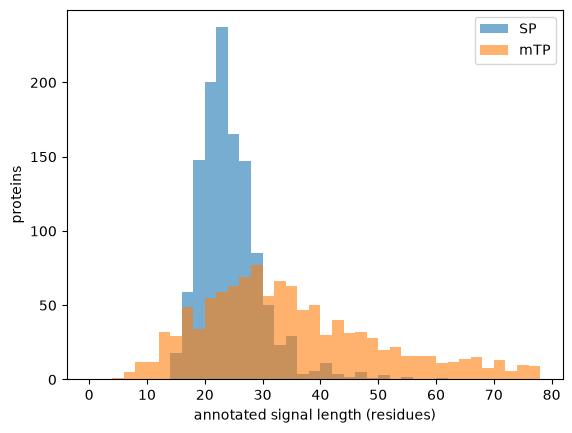

In [ ]:
for lab in ["SP", "mTP"]:
    plt.hist(tp.loc[tp["label"] == lab, "signal_len"], bins=range(0, 80, 2), alpha=0.6, label=lab)
plt.xlabel("annotated signal length (residues)"); plt.ylabel("proteins"); plt.legend();
print(tp.groupby("label")["signal_len"].median())

**Answer.** Bacteria have no mitochondria (mitochondria *descend* from bacteria). Signal peptides
are short and tightly distributed (median ≈ 23 residues); transit peptides are longer and much more
variable (median ≈ 33, some beyond our 50-residue window).

## Part 2 - Data mining along the sequence

Let us average some residue properties **position by position** within each class.
First, hydrophobicity on the Kyte-Doolittle scale (positive = hydrophobic).

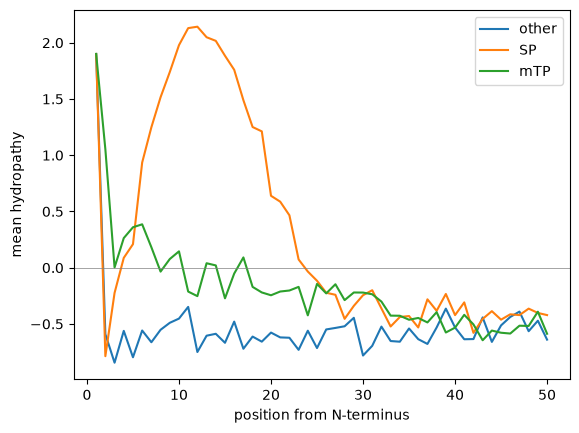

In [ ]:
def position_profile(seqs, value):
    """Mean of value(residue) at each of the 50 positions."""
    return np.array([[value(a) for a in s] for s in seqs]).mean(axis=0)

pos = np.arange(1, 51)
for lab in LABELS:
    seqs = tp.loc[tp["label"] == lab, "nterm"]
    plt.plot(pos, position_profile(seqs, KYTE_DOOLITTLE.get), label=lab)
plt.axhline(0, color="grey", lw=0.5)
plt.xlabel("position from N-terminus"); plt.ylabel("mean hydropathy"); plt.legend();

✏️ **Exercise 2.1.** Make the same plot for **charge**: the fraction of positive residues (R, K) and,
in a second panel, of negative residues (D, E). *Hint:* `value = lambda a: a in "RK"` works because
`True` counts as 1.

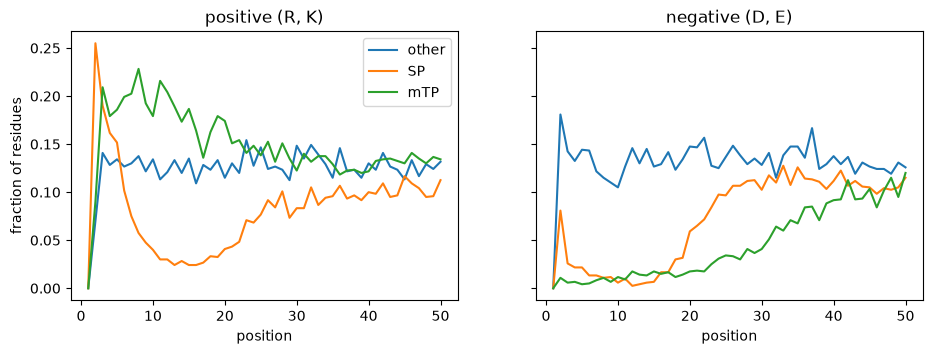

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, residues, title in [(axes[0], "RK", "positive (R, K)"), (axes[1], "DE", "negative (D, E)")]:
    for lab in LABELS:
        seqs = tp.loc[tp["label"] == lab, "nterm"]
        ax.plot(pos, position_profile(seqs, lambda a: a in residues), label=lab)
    ax.set_title(title); ax.set_xlabel("position")
axes[0].set_ylabel("fraction of residues"); axes[0].legend();

❓ Describe the "address label" of each class in words, from these plots.

**Answer.** **SP**: a few positive residues right at the start (n-region), then a strongly
**hydrophobic core** around positions 5-20 (h-region), then a return to normal around the
cleavage site (≈ 20-25). **mTP**: rich in **positive** charges (Arg, Lys) and almost **no negative**
ones over the first ~30 residues, only moderately hydrophobic - it forms an amphipathic helix.
**other**: flat profiles, average composition. The information is concentrated in the first
20-30 residues, and *where* things are matters.

## Part 3 - A composition baseline

Before the neural network, a simple baseline: the amino-acid composition of the first *n* residues,
fed to logistic regression. We keep a fixed 25% test set for the whole session.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

y_all = tp["label"].map({lab: i for i, lab in enumerate(LABELS)}).values
idx_train, idx_test = train_test_split(np.arange(len(tp)), test_size=0.25,
                                       stratify=y_all, random_state=RNG)

def composition_baseline(n):
    Xc = np.vstack(tp["nterm"].map(lambda s: aa_composition(s[:n])))
    clf = LogisticRegression(max_iter=3000).fit(Xc[idx_train], y_all[idx_train])
    return accuracy_score(y_all[idx_test], clf.predict(Xc[idx_test]))

print(f"composition of the first 50 residues: accuracy = {composition_baseline(50):.3f}")

composition of the first 50 residues: accuracy = 0.802


✏️ **Exercise 3.1.** Try n = 10, 15, 20, 25, 30, 40, 50. Which window works best? Does this agree
with Part 2?

In [ ]:
for n in [10, 15, 20, 25, 30, 40, 50]:
    print(f"n = {n:2d}  accuracy = {composition_baseline(n):.3f}")

n = 10  accuracy = 0.714
n = 15  accuracy = 0.808
n = 20  accuracy = 0.861
n = 25  accuracy = 0.873
n = 30  accuracy = 0.863


n = 40  accuracy = 0.838
n = 50  accuracy = 0.802


**Answer.** The best window is around 20-30 residues (≈ 0.87), better than using all 50 (≈ 0.80):
beyond the signal, the residues are just noise that dilutes it. This is a hint that **position**
matters - which composition cannot represent, except through the crude choice of *n*.

## Part 4 - Encoding sequences for a neural network

A neural network needs numbers. **One-hot encoding**: each residue becomes a vector of 20 zeros with
a single 1 at the position of that amino acid. A 50-residue N-terminus becomes a 50 x 20 matrix,
and the whole dataset a 3-dimensional array (proteins x positions x amino acids) - a **tensor**.

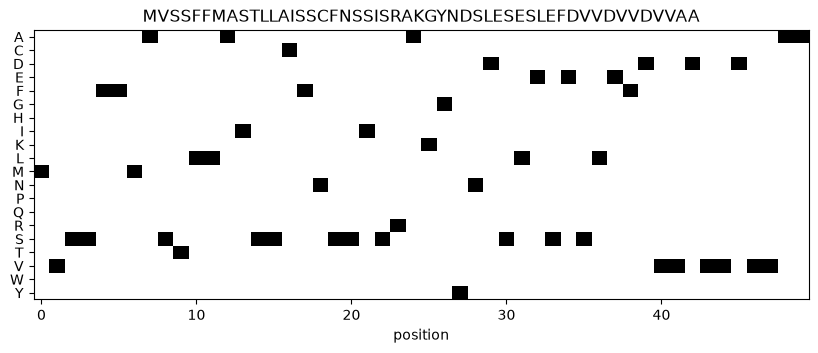

In [ ]:
aa_index = {a: i for i, a in enumerate(AA)}

def one_hot(seq):
    m = np.zeros((len(seq), 20), dtype=np.float32)
    m[np.arange(len(seq)), [aa_index[a] for a in seq]] = 1
    return m

example = tp.loc[tp["label"] == "SP", "nterm"].iloc[0]
plt.figure(figsize=(10, 3.5))
plt.imshow(one_hot(example).T, cmap="Greys", aspect="auto")
plt.yticks(range(20), AA); plt.xlabel("position"); plt.title(example);

In [ ]:
X_all = torch.tensor(np.stack(tp["nterm"].map(one_hot)))   # (3600, 50, 20)
Y_all = torch.tensor(y_all)                                 # (3600,) class 0/1/2
X_train, Y_train = X_all[idx_train], Y_all[idx_train]
X_test, Y_test = X_all[idx_test], Y_all[idx_test]
print(X_train.shape, X_test.shape)

torch.Size([2700, 50, 20]) torch.Size([900, 50, 20])


## Part 5 - A recurrent neural network

A **recurrent neural network (RNN)** reads the sequence one residue at a time, left to right, and
keeps a **hidden state** $h_t$, a vector that summarises what it has seen so far:

$$ h_t = f(x_t, h_{t-1}) \qquad t = 1, \dots, 50 $$

The same function $f$ (same weights) is applied at every position, so the network can detect a
pattern wherever it occurs. We use a **GRU** (gated recurrent unit), a type of RNN with "gates" that
decide what to remember and what to forget - this makes training much easier than with a plain RNN.
After the last residue, a linear layer turns $h_{50}$ into 3 scores, one per class.

```
 M -> [GRU] -> h1
 K -> [GRU] -> h2          (the same GRU, applied 50 times)
 ...
 A -> [GRU] -> h50 -> [linear] -> scores for other / SP / mTP
```

In [ ]:
class TargetingRNN(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.gru = nn.GRU(input_size=20, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, len(LABELS))

    def forward(self, x):                    # x: (batch, 50, 20)
        states, h_last = self.gru(x)         # states: (batch, 50, hidden) - h_t at every position
        return self.head(h_last[-1])         # (batch, 3) class scores ("logits")

    def predict_along(self, x):
        """Class probabilities after reading 1, 2, ..., 50 residues: (batch, 50, 3)."""
        states, _ = self.gru(x)
        return torch.softmax(self.head(states), dim=-1)

torch.manual_seed(RNG)
model = TargetingRNN(hidden=32)
print(model)
print(sum(p.numel() for p in model.parameters()), "trainable parameters")

TargetingRNN(
  (gru): GRU(20, 32, batch_first=True)
  (head): Linear(in_features=32, out_features=3, bias=True)
)
5283 trainable parameters


Training: show the network small **batches** of 64 sequences, compute the **cross-entropy loss**
(how wrong its class probabilities are), and let the **Adam** optimiser nudge every weight to reduce
it. One pass over the training set is an **epoch**. We record the accuracy after every epoch.

(We watch the test accuracy here for teaching purposes only. In a real project you would choose
the number of epochs on a separate *validation* set and touch the test set once at the very end.)

,train accuracy,test accuracy,train loss,test loss
epoch,,,,
13,0.949,0.942,0.141,0.198
14,0.972,0.952,0.091,0.159
15,0.965,0.944,0.101,0.149


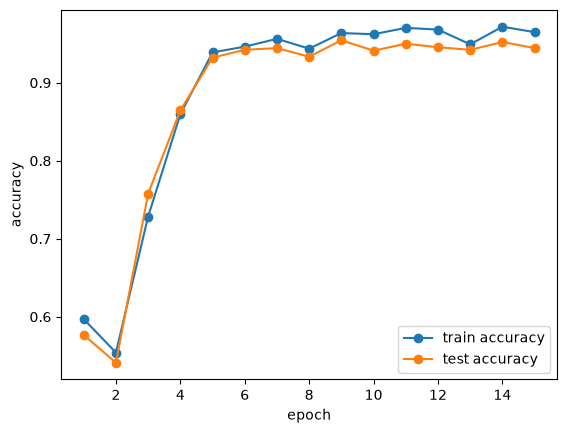

In [ ]:
def accuracy(model, X, Y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(dim=1) == Y).float().mean().item()

def mean_loss(model, X, Y):
    model.eval()
    with torch.no_grad():
        return nn.functional.cross_entropy(model(X), Y).item()

def train(model, X_tr, Y_tr, X_te, Y_te, epochs=15, lr=0.01, batch_size=64, seed=RNG, weight_decay=0.0):
    torch.manual_seed(seed)
    optimiser = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(X_tr))
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            loss = loss_fn(model(X_tr[batch]), Y_tr[batch])
            optimiser.zero_grad()            # forget the previous gradients
            loss.backward()                  # compute d(loss)/d(weight) for every weight
            optimiser.step()                 # update the weights
        history.append({"epoch": epoch,
                        "train accuracy": accuracy(model, X_tr, Y_tr),
                        "test accuracy": accuracy(model, X_te, Y_te),
                        "train loss": mean_loss(model, X_tr, Y_tr),
                        "test loss": mean_loss(model, X_te, Y_te)})
    return pd.DataFrame(history).set_index("epoch")

history = train(model, X_train, Y_train, X_test, Y_test, epochs=15)
ACC = ["train accuracy", "test accuracy"]
history[ACC].plot(marker="o"); plt.ylabel("accuracy");
history.tail(3)

GRU test accuracy = 0.944
              precision    recall  f1-score   support

          SP      0.970     0.963     0.967       300
         mTP      0.908     0.957     0.932       300
       other      0.958     0.913     0.935       300

    accuracy                          0.944       900
   macro avg      0.945     0.944     0.945       900
weighted avg      0.945     0.944     0.945       900



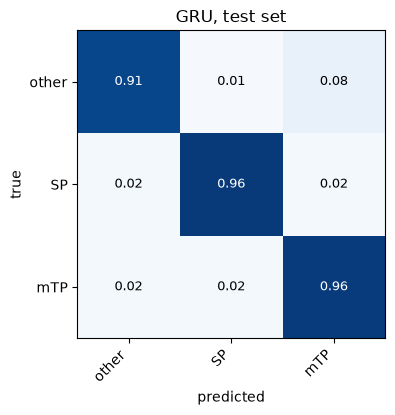

In [ ]:
model.eval()
with torch.no_grad():
    pred_test = model(X_test).argmax(dim=1).numpy()
print(f"GRU test accuracy = {accuracy_score(Y_test, pred_test):.3f}")
names = np.array(LABELS)
from sklearn.metrics import classification_report
print(classification_report(names[Y_test.numpy()], names[pred_test], digits=3))
plot_confusion(names[Y_test.numpy()], names[pred_test], LABELS, title="GRU, test set");

❓ How does the GRU compare with the best composition baseline of Part 3? Which classes get confused?

✏️ **Exercise 5.1.** Train a tiny network (`hidden=4`) and a bigger one (`hidden=128`), with
`torch.manual_seed(RNG)` before creating each. Compare training and test accuracy curves. Does
the big one overfit? (The bigger one takes ~30 s.)

In [ ]:
hists = {32: history}
for h in [4, 128]:
    torch.manual_seed(RNG)
    hists[h] = hist_h = train(TargetingRNN(hidden=h), X_train, Y_train, X_test, Y_test, epochs=15)
    print(f"hidden={h:3d}: final train acc = {hist_h['train accuracy'].iloc[-1]:.3f}, "
          f"test acc = {hist_h['test accuracy'].iloc[-1]:.3f}, best test = {hist_h['test accuracy'].max():.3f}")

hidden=  4: final train acc = 0.944, test acc = 0.933, best test = 0.934


hidden=128: final train acc = 0.988, test acc = 0.937, best test = 0.952


**Answer.** The GRU reaches ≈ 0.94 test accuracy, against ≈ 0.87 for the best composition window:
reading the residues *in order* helps. SP is recognised best (precision and recall ≈ 0.97); most remaining errors are "other" proteins
predicted as mTP (weak transit-like N-termini, or perhaps unannotated dual-targeted proteins). With 4 hidden units the network is still decent but lower; with
128 the training accuracy approaches 1 while the test accuracy stalls or dips - overfitting.

## Part 6 - Does the order matter?

A clean control experiment: **shuffle the residues within each sequence**. The composition of
every sequence is unchanged, but the order is destroyed. If the GRU only used composition, its
accuracy would not change.

✏️ **Exercise 6.1.** Complete the code: build the shuffled one-hot tensor, train a fresh
`TargetingRNN(hidden=32)` on it (same train/test indices), and compare.

MVSSFFMASTLLAISSCFNSSISRAKGYNDSLESESLEFDVVDVVDVVAA
NRLFSSEASGVLVSLDSYMIFSVCESNMSVAFEKVTVDIAADAFSDVSSL


real sequences:     final test accuracy = 0.944
shuffled sequences: final test accuracy = 0.796, train = 0.866


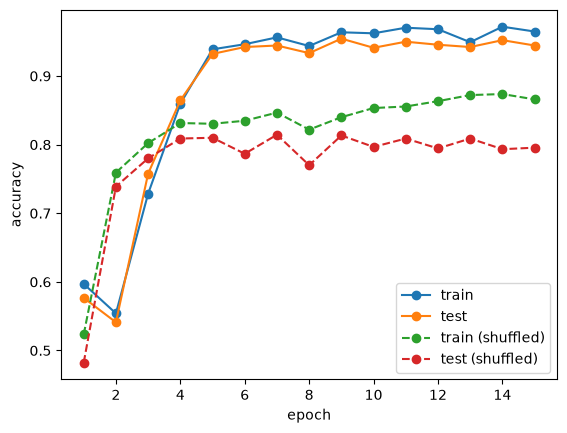

In [ ]:
rng = np.random.default_rng(RNG)
shuffled = tp["nterm"].map(lambda s: "".join(rng.permutation(list(s))))
print(tp["nterm"].iloc[0]); print(shuffled.iloc[0])

X_shuf = torch.tensor(np.stack(shuffled.map(one_hot)))
torch.manual_seed(RNG)
history_shuf = train(TargetingRNN(hidden=32), X_shuf[idx_train], Y_train,
                     X_shuf[idx_test], Y_test, epochs=15)
print(f"real sequences:     final test accuracy = {history['test accuracy'].iloc[-1]:.3f}")
print(f"shuffled sequences: final test accuracy = {history_shuf['test accuracy'].iloc[-1]:.3f}, "
      f"train = {history_shuf['train accuracy'].iloc[-1]:.3f}")

ax = history[ACC].plot(marker="o")
history_shuf[ACC].plot(marker="o", style="--", ax=ax)
plt.legend(["train", "test", "train (shuffled)", "test (shuffled)"]); plt.ylabel("accuracy");

**Answer.** On shuffled sequences the GRU drops to ≈ 0.80 - the level of the composition baseline
on 50 residues - and the gap between training and test accuracy widens (it can only memorise).
The ≈ 0.14 extra accuracy of the real model comes entirely from the **order** of the residues.

## Part 7 - Watching the RNN read

Because the GRU produces a hidden state at every position, we can ask: *what would it predict if
the sequence stopped here?* `predict_along` applies the final layer to $h_1, h_2, \dots, h_{50}$.

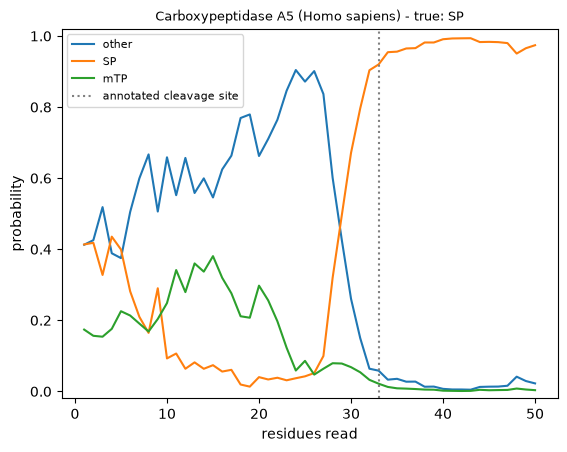

In [ ]:
def plot_reading(i):
    """Class probabilities as the trained model reads test protein number i."""
    row = tp.iloc[idx_test[i]]
    with torch.no_grad():
        probs = model.predict_along(X_test[i:i + 1])[0].numpy()     # (50, 3)
    for k, lab in enumerate(LABELS):
        plt.plot(pos, probs[:, k], label=lab)
    if row["signal_len"] > 0:
        plt.axvline(row["signal_len"], color="grey", ls=":", label="annotated cleavage site")
    plt.ylim(-0.02, 1.02); plt.xlabel("residues read"); plt.ylabel("probability")
    plt.title(f"{row['protein_name'][:50]} ({row['organism']}) - true: {row['label']}", fontsize=9)
    plt.legend(fontsize=8)

plot_reading(int(np.flatnonzero(Y_test.numpy() == LABELS.index("SP"))[0]))

❓ On average, after how many residues is the network confident about a signal peptide? Compare with
the hydrophobicity profile of Part 2.

**Answer.** On average the network is confident (P > 0.8) after ≈ 16 residues for SPs - as soon as
the hydrophobic core has been read - and ≈ 19 for mTPs. For *other* it takes ≈ 30 residues: the
absence of a signal can only be concluded after reading past the place where one would be.
The network has rediscovered, by itself, the features that biologists described from experiments.

other: mean P(true class) first exceeds 0.8 after 32 residues
SP   : mean P(true class) first exceeds 0.8 after 16 residues
mTP  : mean P(true class) first exceeds 0.8 after 19 residues


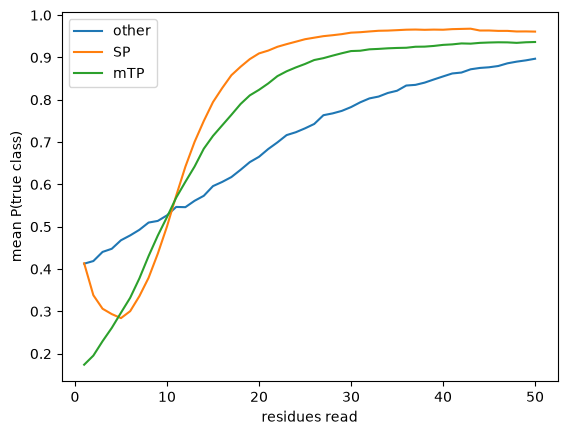

In [ ]:
# average probability of the true class vs. number of residues read, per class
with torch.no_grad():
    along = model.predict_along(X_test).numpy()                    # (n_test, 50, 3)
for k, lab in enumerate(LABELS):
    sel = Y_test.numpy() == k
    curve = along[sel, :, k].mean(axis=0)
    plt.plot(pos, curve, label=lab)
    print(f"{lab:5s}: mean P(true class) first exceeds 0.8 after {np.argmax(curve > 0.8) + 1} residues")
plt.xlabel("residues read"); plt.ylabel("mean P(true class)"); plt.legend();

### Which residues does the network look at?

**Saliency**: how much does the score of the true class change if a residue changes? We take the
gradient of the score with respect to the one-hot input (the same `backward()` used in training,
but with respect to the input instead of the weights) and multiply it by the input, which keeps
the value of the residue that is actually there. Averaged over the test proteins of each class, this gives a
profile along the sequence.

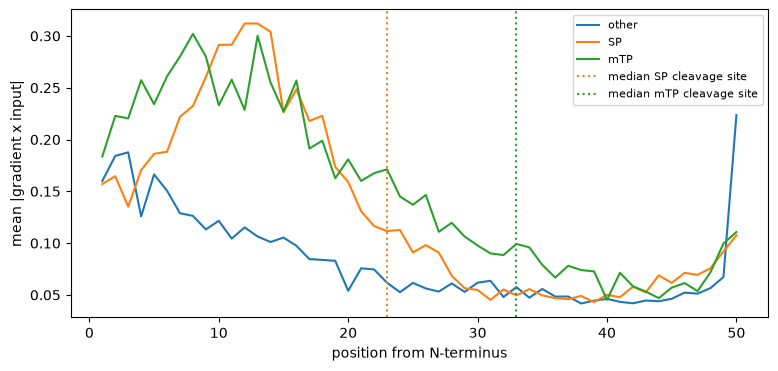

In [ ]:
model.eval()
y_te = Y_test.numpy()
colours = {"other": "tab:blue", "SP": "tab:orange", "mTP": "tab:green"}
X_in = X_test.clone().requires_grad_(True)
scores = model(X_in)                                    # (n_test, 3)
scores.gather(1, Y_test[:, None]).sum().backward()      # d(true-class score) / d(input)
saliency = (X_in.grad * X_test).sum(dim=2).abs().numpy()   # (n_test, 50): one value per residue

fig, ax = plt.subplots(figsize=(9, 4))
for k, lab in enumerate(LABELS):
    ax.plot(pos, saliency[y_te == k].mean(axis=0), color=colours[lab], label=lab)
for lab in ["SP", "mTP"]:
    med = tp.loc[tp["label"] == lab, "signal_len"].median()
    ax.axvline(med, color=colours[lab], ls=":", label=f"median {lab} cleavage site")
ax.set_xlabel("position from N-terminus"); ax.set_ylabel("mean |gradient x input|")
ax.legend(fontsize=8);

❓ Which positions matter for each class? Compare with the hydropathy and charge profiles of Part 2.

**Answer.** The saliency is concentrated in the first ~25-30 residues, where the signals are, and
falls off towards the cleavage sites; residues far beyond them hardly influence the decision. This
is what the profiles of Part 2 and the best composition window of Part 3 suggested, but here the
network found it without being told. Saliency maps are a simple form of **explainable AI**: they say
*where* the model looks, not *why*. The spike at position 50 is an artefact of reading left to right:
the last residue enters the final state directly, without passing through the gates many times.
A bidirectional RNN (as in TargetP) reads the sequence in both directions and avoids this.

## Summary

* Positional **data mining** (profiles along the sequence) revealed the signals before any model.
* A composition baseline reaches ≈ 0.80-0.87; a small **GRU** reading one-hot residues in order
  reaches ≈ 0.94, with ~5000 parameters and a few seconds of CPU.
* The **shuffled-sequence control** proves that the gain comes from residue order.
* RNNs give a prediction after every residue, so we can watch *where* the decision is made; a
  saliency map shows which residues it relies on.
* Real tools (SignalP 6, TargetP 2, DeepLoc 2) use bidirectional LSTMs, attention, or **protein
  language models** (transformers pre-trained on millions of sequences) - the same ideas, scaled up.

### If you have time: does it work across species?

✏️ Train on all organisms **except human** and test on the human proteins. Compare with the
random split. Then try training on *Arabidopsis* only and testing on yeast.

In [ ]:
is_human = torch.tensor((tp["organism"] == "Homo sapiens").values)
torch.manual_seed(RNG)
hist_sp = train(TargetingRNN(hidden=32), X_all[~is_human], Y_all[~is_human],
                X_all[is_human], Y_all[is_human], epochs=15)
print(f"train non-human -> test human: accuracy = {hist_sp['test accuracy'].iloc[-1]:.3f}")

is_plant = torch.tensor((tp["organism"] == "Arabidopsis thaliana").values)
is_yeast = torch.tensor((tp["organism"] == "Saccharomyces cerevisiae").values)
torch.manual_seed(RNG)
hist_py = train(TargetingRNN(hidden=32), X_all[is_plant], Y_all[is_plant],
                X_all[is_yeast], Y_all[is_yeast], epochs=15)
print(f"train Arabidopsis -> test yeast: accuracy = {hist_py['test accuracy'].iloc[-1]:.3f}")

train non-human -> test human: accuracy = 0.885


train Arabidopsis -> test yeast: accuracy = 0.915


**Answer.** Trained without human proteins, the GRU still reaches ≈ 0.89 on human; trained on
*Arabidopsis* alone, ≈ 0.92 on yeast. Lower than the random split (≈ 0.94) but close: targeting
signals are conserved across eukaryotes, because the import machineries (SRP/Sec61, TOM/TIM) are.
Testing on a group the model has never seen (here a species, in class 2 a protein family) is the
honest way to measure generalisation.

## References and data sources

**Data**

* Enzyme and targeting tables: reviewed entries of UniProtKB/Swiss-Prot (UniProt Consortium 2023), downloaded with the UniProt REST API on 2026-11-10 from human, *E. coli* K-12, yeast, *Arabidopsis* and *B. subtilis*; Swiss-Prot changes at every release, so the committed TSVs are the reference. See `course/README.md` and `data_prep/`. Labels come from the `SIGNAL` and `TRANSIT` feature annotations.

**Further reading**

* Almagro Armenteros JJ, Salvatore M, Emanuelsson O, et al. (2019). Detecting sequence signals in targeting peptides using deep learning. *Life Sci Alliance* 2:e201900429. [doi:10.26508/lsa.201900429](https://doi.org/10.26508/lsa.201900429) — TargetP 2.0, a bidirectional LSTM for the same three classes
* Teufel F, Almagro Armenteros JJ, Johansen AR, et al. (2022). SignalP 6.0 predicts all five types of signal peptides using protein language models. *Nat Biotechnol* 40:1023–1025. [doi:10.1038/s41587-021-01156-3](https://doi.org/10.1038/s41587-021-01156-3) — SignalP 6.0, signal peptides with a protein language model
* Cho K, van Merriënboer B, Gulcehre C, et al. (2014). Learning phrase representations using RNN encoder–decoder for statistical machine translation. *Proc EMNLP* 1724–1734. [doi:10.3115/v1/D14-1179](https://doi.org/10.3115/v1/D14-1179) — the GRU
* Kapoor S, Narayanan A (2023). Leakage and the reproducibility crisis in machine-learning-based science. *Patterns* 4:100804. [doi:10.1016/j.patter.2023.100804](https://doi.org/10.1016/j.patter.2023.100804) — leakage; here, why we test on held-out species